In [2]:
# Standard library imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, contingency

In [3]:
subscriptions = pd.read_csv('../data/raw data/subscriptions.csv')
usage = pd.read_csv('../data/raw data/usage.csv')

In [ ]:
subscriptions.info()

In [ ]:
usage.info()

In [ ]:
# Missing values.
subscriptions.isna().sum()

In [ ]:
usage.isna().sum()

In [4]:
# Missing values as percent.
missing_count = usage['minutes_active'].isna().sum()
missing_percent = (missing_count / len(usage)) * 100
print(f'{missing_percent:.2f}% of values in usage.csv contains missing values.')

1.65% of values in usage.csv contains missing values.


In [ ]:
# Percent of churned customers without a cancel reason i.e. missing values. Remaining missing values is due to membership still being active.
subs_missing = subscriptions.loc[subscriptions['churned'] == 'yes', 'cancel_reason'].isna().sum()
subs_missing_percent = (subs_missing / len(subscriptions)) * 100
print(f"{subs_missing_percent:.2f}% of customers who cancelled didn't specify a reason.")

In [4]:
# Dealing with missing values.
# Replacing missing minutes_active values with 0 where workouts_completed is 0.
usage.loc[usage['workouts_completed'] == 0, ['minutes_active']] = usage.loc[usage['workouts_completed'] == 0, ['minutes_active']].fillna(0)
usage = usage.dropna()

missing_values = (subscriptions['churned'] == 'yes') & (subscriptions['cancel_reason'].isna())
subscriptions.loc[missing_values, 'cancel_reason'] = subscriptions.loc[missing_values, 'cancel_reason'].fillna("not_specified")

In [6]:
subscriptions['plan_tier'] = subscriptions['plan_tier'].str.lower()

In [5]:
# Checking missing values again.
print(subscriptions.isna().sum())
print(usage.isna().sum())

customer_id               0
signup_date               0
plan_type                 0
plan_tier                 0
monthly_price             0
acquisition_channel       0
primary_device            0
age_group                 0
churned                   0
churn_date             2432
cancel_reason          2432
dtype: int64
customer_id           0
month                 0
workouts_completed    0
minutes_active        0
classes_booked        0
support_tickets       0
dtype: int64


In [ ]:
# Univariate Analysis

In [7]:
def pie_chart(data:pd.Series, labels:pd.Index,
              title:str, font_loc:str='center',
              fontsize:int=12, colors=sns.color_palette,
              percent:str='%.2f%%', shadow:bool=True):

    chart = plt.pie(data, labels=labels, colors=colors, autopct=percent, shadow=shadow)
    plt.title(title, loc=font_loc, fontsize=fontsize)
    plt.show()

In [7]:
# Filtering out columns not needed for visualizations.
filtered_subs = subscriptions.drop(['customer_id', 'signup_date', 'monthly_price', 'churn_date'], axis=1)

active_customers = filtered_subs.loc[subscriptions['churned'] == 'no']
#Dropping cancel_reason since they're still customers.
active_customers = active_customers.drop('cancel_reason', axis=1)

churned_customers = filtered_subs.loc[filtered_subs['churned'] == 'yes']

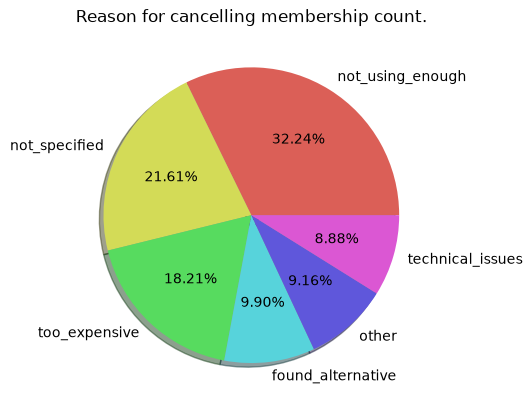

In [78]:
churn_reason_count = churned_customers['cancel_reason'].value_counts()
color = sns.color_palette('hls')
pie_chart(churn_reason_count, labels=churn_reason_count.index,
                             title='Reason for cancelling membership count.',
                             colors=color);

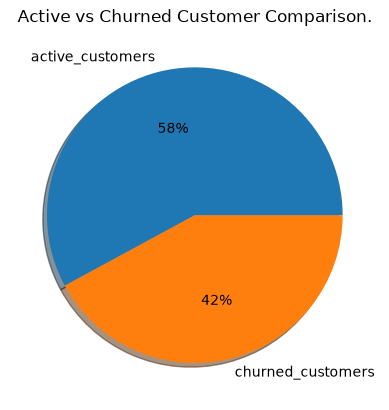

In [83]:
customer_comparison = filtered_subs['churned'].value_counts()
colors = sns.color_palette('tab10')[:2]
labels = ('active_customers', 'churned_customers')
pie_chart(customer_comparison, labels=labels,
          title='Active vs Churned Customer Comparison.',
          colors=colors, percent='%.0f%%');

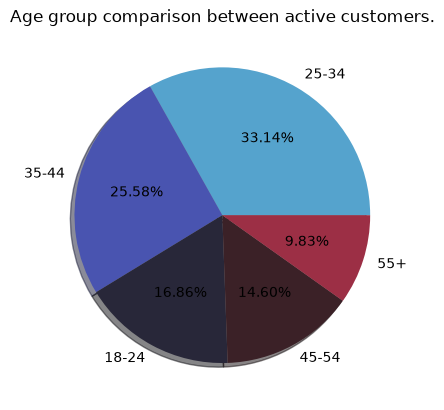

In [10]:
# Age group comparison for active customers.
active_age_comparison = active_customers['age_group'].value_counts()
colors = sns.color_palette(palette='icefire')
pie_chart(active_age_comparison, labels=active_age_comparison.index,
          title='Age group comparison between active customers.',
          colors=colors);

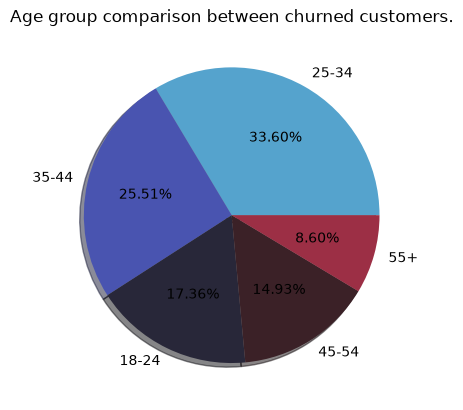

In [13]:
# Age group comparison for churned customers.
churned_age_comparison = churned_customers['age_group'].value_counts()
pie_chart(churned_age_comparison, labels=churned_age_comparison.index,
          title='Age group comparison between churned customers.',
          colors=colors);

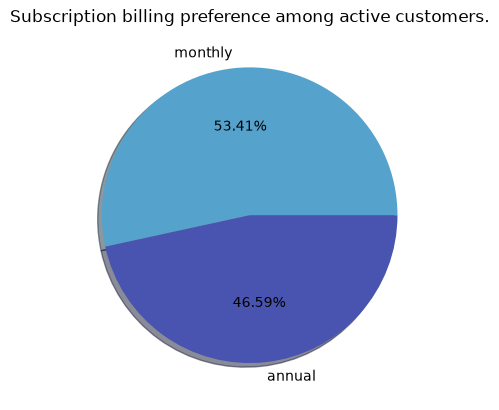

In [14]:
# Subscription billing period preference for active customers.
active_billing_period = active_customers['plan_type'].value_counts()

pie_chart(active_billing_period, active_billing_period.index,
          title='Subscription billing preference among active customers.',
          colors=colors[:2])

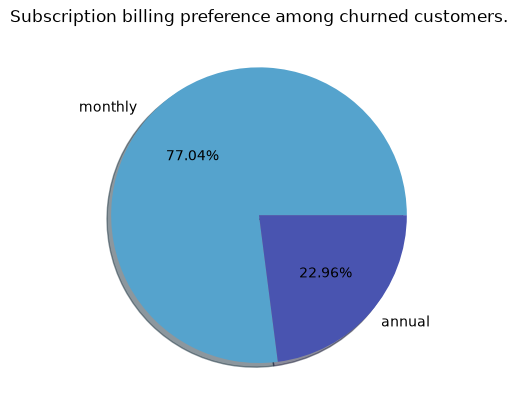

In [15]:
# Subscription billing period preference for churned customers.
churned_billing_period = churned_customers['plan_type'].value_counts()

pie_chart(churned_billing_period, labels=churned_billing_period.index,
          title='Subscription billing preference among churned customers.',
          colors=colors[:2])

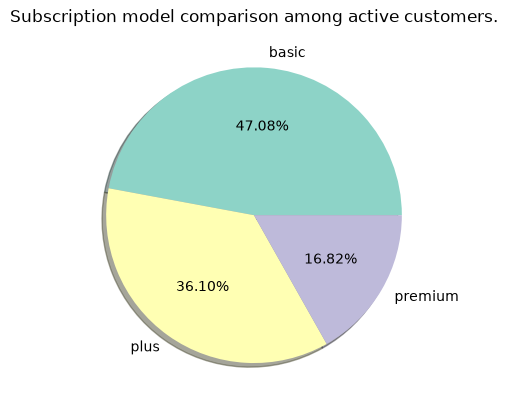

In [21]:
active_subs_model = active_customers['plan_tier'].value_counts()
colors = sns.color_palette('Set3')

pie_chart(active_subs_model, labels=active_subs_model.index,
          title='Subscription model comparison among active customers.',
          colors=colors)

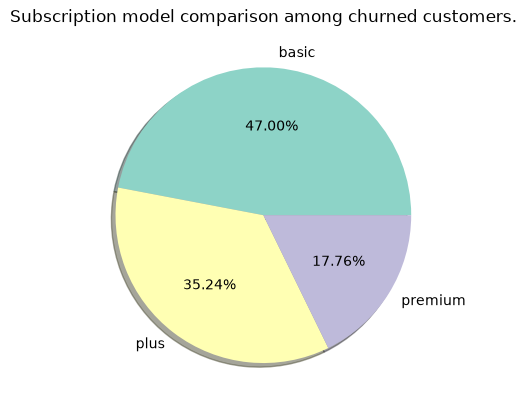

In [22]:
churned_subs_model = churned_customers['plan_tier'].value_counts()

pie_chart(churned_subs_model, labels=churned_subs_model.index,
          title='Subscription model comparison among churned customers.',
          colors=colors)

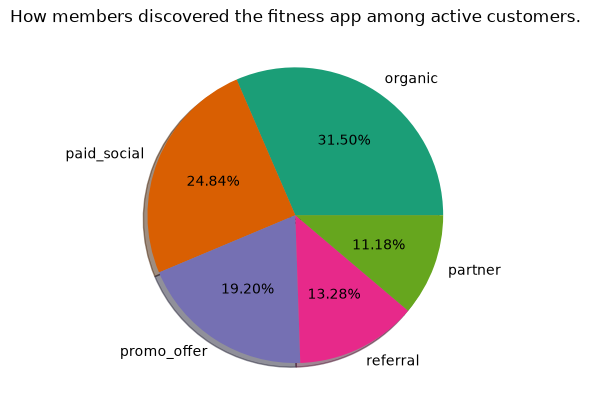

In [23]:
active_acquisition = active_customers['acquisition_channel'].value_counts()
colors = sns.color_palette('Dark2')

pie_chart(active_acquisition, labels=active_acquisition.index,
          title='How members discovered the fitness app among active customers.',
          colors=colors)

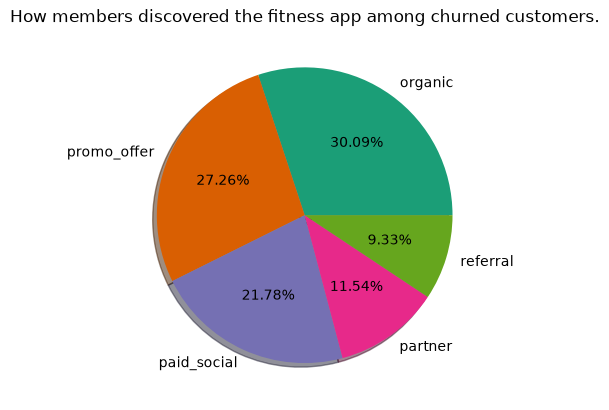

In [29]:
churned_acquisition = churned_customers['acquisition_channel'].value_counts()
colors = sns.color_palette('Dark2')

pie_chart(churned_acquisition, labels=churned_acquisition.index,
          title='How members discovered the fitness app among churned customers.',
          colors=colors)

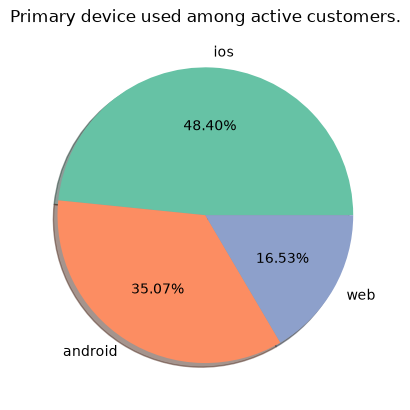

In [26]:
active_primary_device = active_customers['primary_device'].value_counts()
device_color = sns.color_palette('Set2')

pie_chart(active_primary_device, labels=active_primary_device.index,
          title='Primary device used among active customers.',
          colors=device_color)

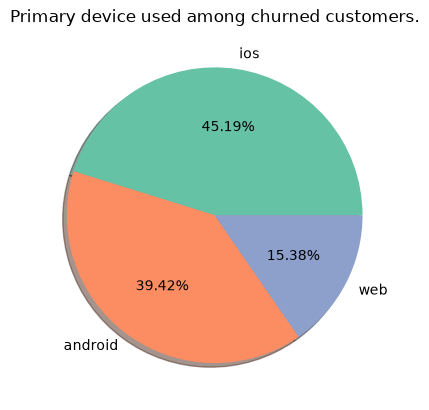

In [27]:
churned_primary_device = churned_customers['primary_device'].value_counts()

pie_chart(churned_primary_device, labels=churned_primary_device.index,
          title='Primary device used among churned customers.',
          colors=device_color)

In [52]:
# Probability that customers on monthly plan will churn out.
monthly_probability = (churned_customers['plan_type'] == 'monthly').sum() / (filtered_subs['plan_type'] == 'monthly').sum()
print(monthly_probability * 100)

51.18376550169109


In [55]:
# Probability that customers on annual plan will churn out.
annual_probability = (churned_customers['plan_type'] == 'annual').sum() / (filtered_subs['plan_type'] == 'annual').sum()
print(annual_probability * 100)

26.380766731643924


# Chi Squared Test

In [8]:
# Testing if there is a correlation between subscription preference and churning out.
observed_df = pd.crosstab(filtered_subs['churned'], filtered_subs['plan_type'])
observed = observed_df.to_numpy()
alpha = 0.05

In [9]:
observed

array([[1133, 1299],
       [ 406, 1362]])

In [10]:
chi_squared, p_value, degree_of_freedom, expected = chi2_contingency(observed)

In [11]:
print(f'The Chi squared value is {chi_squared:.3f}.')
print(f'The p value is {str(p_value)[:5]}.')
print(f'Degree(s) of Freedom; {degree_of_freedom}.')
print(f'The expected values are; \n {expected}.')

The Chi squared value is 245.074.
The p value is 3.078.
Degree(s) of Freedom; 1.
The expected values are; 
 [[ 891.15428571 1540.84571429]
 [ 647.84571429 1120.15428571]].


In [12]:
if p_value > alpha:
    print('The Categorical variables are independent variables i.e 1 variable dont affect the other.')
else:
    print('The categorical variables are dependent variables i.e 1 variable do affect the other variable.')

The categorical variables are dependent variables i.e 1 variable do affect the other variable.


# Cramer's V

In [13]:
# Now that we found out that subscription billing period preference are dependent variables, we want to figure out to what degree they are dependent.
# To achieve this we use the Cramer's V formula.

n = np.sum(observed)
minimum_dimensions = min(observed.shape) - 1

score = np.sqrt((chi_squared / n) / minimum_dimensions)
score

np.float64(0.24155955382806477)

In [14]:
print(contingency.association(observed))

0.24205999684306292
